### Fluency Model (Classification)   

In [1]:

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [2]:

# Load the dataset
data_path = "../data/raw/"
df = pd.read_csv(data_path + "language_learning_fluency.csv")

# Define the target
target = "reached_fluency"

# Define the columns to exclude
excluded_columns = [
    "learner_id",
    "reached_fluency",
    "cefr_level",
    "dropped_out"
]

# Create input features and target
X = df.drop(columns=excluded_columns)
y = df[target]

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())


Input shape: (45000, 14)
Target shape: (45000,)

Target distribution:
reached_fluency
0    28907
1    16093
Name: count, dtype: int64


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (36000, 14)
Testing features: (9000, 14)
Training target: (36000,)
Testing target: (9000,)


In [5]:

# Create the Logistic Regression model
fluency_model = LogisticRegression(max_iter=1000)

# Train the model
fluency_model.fit(X_train, y_train)

print("Fluency model trained successfully!")

Fluency model trained successfully!


c:\Users\pdhav\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [6]:

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline


In [7]:

fluency_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

fluency_model.fit(X_train, y_train)

print("Fluency model trained successfully!")


Fluency model trained successfully!


In [8]:

# Predict fluency for the test data
y_pred = fluency_model.predict(X_test)

print("Predictions generated successfully!")
print("First 10 actual values:", y_test.iloc[:10].tolist())
print("First 10 predicted values:", y_pred[:10].tolist())


Predictions generated successfully!
First 10 actual values: [0, 1, 0, 0, 1, 0, 1, 1, 1, 1]
First 10 predicted values: [0, 1, 0, 0, 1, 0, 1, 1, 0, 1]


In [9]:

accuracy = accuracy_score(y_test, y_pred)

print("Fluency Model Accuracy:", round(accuracy * 100, 2), "%")

Fluency Model Accuracy: 88.16 %


In [10]:

# Display the classification report
print(classification_report(
    y_test,
    y_pred,
    target_names=["Did not reach fluency", "Reached fluency"]
))


                       precision    recall  f1-score   support

Did not reach fluency       0.89      0.92      0.91      5781
      Reached fluency       0.86      0.80      0.83      3219

             accuracy                           0.88      9000
            macro avg       0.88      0.86      0.87      9000
         weighted avg       0.88      0.88      0.88      9000



In [11]:

# Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[5345  436]
 [ 630 2589]]


In [12]:

# Store the baseline evaluation results
fluency_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Non-fluent Precision",
        "Non-fluent Recall",
        "Non-fluent F1-score",
        "Fluent Precision",
        "Fluent Recall",
        "Fluent F1-score"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        0.89,
        0.92,
        0.91,
        0.86,
        0.80,
        0.83
    ]
})

fluency_results


,Metric,Score
0,Accuracy,0.881556
1,Non-fluent Precision,0.890000
2,Non-fluent Recall,0.920000
3,Non-fluent F1-score,0.910000
4,Fluent Precision,0.860000
5,Fluent Recall,0.800000
6,Fluent F1-score,0.830000


### Learner Dropout model - (Classification)

In [13]:

# Define the dropout target
target_dropout = "dropped_out"

# Columns to exclude from the input features
excluded_dropout = [
    "learner_id",
    "dropped_out",
    "cefr_level",
    "reached_fluency"
]

# Create input features and target
X_dropout = df.drop(columns=excluded_dropout)
y_dropout = df[target_dropout]

print("Input shape:", X_dropout.shape)
print("Target shape:", y_dropout.shape)

print("\nTarget distribution:")
print(y_dropout.value_counts())


Input shape: (45000, 14)
Target shape: (45000,)

Target distribution:
dropped_out
0    28320
1    16680
Name: count, dtype: int64


In [14]:

# Split the dropout dataset
X_train_dropout, X_test_dropout, y_train_dropout, y_test_dropout = train_test_split(
    X_dropout,
    y_dropout,
    test_size=0.2,
    random_state=42,
    stratify=y_dropout
)

print("Training features:", X_train_dropout.shape)
print("Testing features:", X_test_dropout.shape)
print("Training target:", y_train_dropout.shape)
print("Testing target:", y_test_dropout.shape)


Training features: (36000, 14)
Testing features: (9000, 14)
Training target: (36000,)
Testing target: (9000,)


In [15]:

# Create the dropout classification model
dropout_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Train the model
dropout_model.fit(X_train_dropout, y_train_dropout)

print("Dropout model trained successfully!")


Dropout model trained successfully!


In [16]:

# Predict dropout outcomes for the test data
y_pred_dropout = dropout_model.predict(X_test_dropout)

print("Predictions generated successfully!")
print("First 10 actual values:", y_test_dropout.iloc[:10].tolist())
print("First 10 predicted values:", y_pred_dropout[:10].tolist())


Predictions generated successfully!
First 10 actual values: [1, 0, 1, 1, 0, 0, 1, 0, 0, 1]
First 10 predicted values: [1, 0, 0, 1, 1, 0, 0, 0, 0, 1]


In [17]:

# Calculate dropout model accuracy
accuracy_dropout = accuracy_score(y_test_dropout, y_pred_dropout)

print("Dropout Model Accuracy:", round(accuracy_dropout * 100, 2), "%")


Dropout Model Accuracy: 72.91 %


In [18]:

# Display the classification report
print(classification_report(
    y_test_dropout,
    y_pred_dropout,
    target_names=["Did not drop out", "Dropped out"]
))


                  precision    recall  f1-score   support

Did not drop out       0.76      0.83      0.79      5664
     Dropped out       0.66      0.57      0.61      3336

        accuracy                           0.73      9000
       macro avg       0.71      0.70      0.70      9000
    weighted avg       0.72      0.73      0.72      9000



In [19]:

# Display the confusion matrix
cm_dropout = confusion_matrix(y_test_dropout, y_pred_dropout)

print("Confusion Matrix:")
print(cm_dropout)


Confusion Matrix:
[[4675  989]
 [1449 1887]]


In [20]:

# Store the dropout model's baseline results
dropout_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "No-dropout Precision",
        "No-dropout Recall",
        "No-dropout F1-score",
        "Dropout Precision",
        "Dropout Recall",
        "Dropout F1-score"
    ],
    "Score": [
        accuracy_score(y_test_dropout, y_pred_dropout),
        0.76,
        0.83,
        0.79,
        0.66,
        0.57,
        0.61
    ]
})

dropout_results


,Metric,Score
0,Accuracy,0.729111
1,No-dropout Precision,0.760000
2,No-dropout Recall,0.830000
3,No-dropout F1-score,0.790000
4,Dropout Precision,0.660000
5,Dropout Recall,0.570000
6,Dropout F1-score,0.610000


### CEFR Level (Classification)

In [21]:

# Define the CEFR target
target_cefr = "cefr_level"

# Columns to exclude from input features
excluded_cefr = [
    "learner_id",
    "cefr_level",
    "reached_fluency",
    "dropped_out"
]

# Create input features and target
X_cefr = df.drop(columns=excluded_cefr)
y_cefr = df[target_cefr]

print("Input shape:", X_cefr.shape)
print("Target shape:", y_cefr.shape)

print("\nCEFR level distribution:")
print(y_cefr.value_counts().sort_index())


Input shape: (45000, 14)
Target shape: (45000,)

CEFR level distribution:
cefr_level
A0     5230
A1     6657
A2    10800
B1     6220
B2     6389
C1     5360
C2     4344
Name: count, dtype: int64


In [22]:

# Split the CEFR dataset
X_train_cefr, X_test_cefr, y_train_cefr, y_test_cefr = train_test_split(
    X_cefr,
    y_cefr,
    test_size=0.2,
    random_state=42,
    stratify=y_cefr
)

print("Training features:", X_train_cefr.shape)
print("Testing features:", X_test_cefr.shape)
print("Training target:", y_train_cefr.shape)
print("Testing target:", y_test_cefr.shape)


Training features: (36000, 14)
Testing features: (9000, 14)
Training target: (36000,)
Testing target: (9000,)


In [23]:

# Create the CEFR classification model
cefr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Train the model
cefr_model.fit(X_train_cefr, y_train_cefr)

print("CEFR model trained successfully!")


CEFR model trained successfully!


In [24]:

# Predict CEFR levels for the test data
y_pred_cefr = cefr_model.predict(X_test_cefr)

print("Predictions generated successfully!")
print("First 10 actual levels:", y_test_cefr.iloc[:10].tolist())
print("First 10 predicted levels:", y_pred_cefr[:10].tolist())


Predictions generated successfully!
First 10 actual levels: ['A2', 'A2', 'A2', 'C1', 'B2', 'B1', 'A2', 'C1', 'C1', 'A2']
First 10 predicted levels: ['A2', 'B1', 'A2', 'C1', 'A1', 'B1', 'B2', 'C2', 'A2', 'A2']


In [25]:

# Calculate CEFR model accuracy
accuracy_cefr = accuracy_score(y_test_cefr, y_pred_cefr)

print("CEFR Model Accuracy:", round(accuracy_cefr * 100, 2), "%")


CEFR Model Accuracy: 55.37 %


In [26]:

# Evaluate performance for each CEFR level
print(classification_report(
    y_test_cefr,
    y_pred_cefr,
    labels=["A0", "A1", "A2", "B1", "B2", "C1", "C2"],
    zero_division=0
))


              precision    recall  f1-score   support

          A0       0.78      0.79      0.79      1046
          A1       0.58      0.52      0.55      1331
          A2       0.56      0.72      0.63      2160
          B1       0.38      0.20      0.27      1244
          B2       0.42      0.46      0.44      1278
          C1       0.45      0.43      0.44      1072
          C2       0.71      0.70      0.70       869

    accuracy                           0.55      9000
   macro avg       0.55      0.55      0.54      9000
weighted avg       0.54      0.55      0.54      9000



In [27]:

# Display the confusion matrix
cm_cefr = confusion_matrix(
    y_test_cefr,
    y_pred_cefr,
    labels=["A0", "A1", "A2", "B1", "B2", "C1", "C2"]
)

print("CEFR Confusion Matrix:")
print(cm_cefr)


CEFR Confusion Matrix:
[[ 831  174   40    1    0    0    0]
 [ 228  689  392    4   15    2    1]
 [  10  315 1550  150  123   10    2]
 [   0    5  593  254  315   73    4]
 [   0    1  188  216  587  260   26]
 [   0    0   28   46  319  464  215]
 [   0    0    0    0   33  228  608]]


In [28]:

# Store the CEFR model's baseline results
cefr_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro F1-score",
        "Weighted F1-score"
    ],
    "Score": [
        accuracy_score(y_test_cefr, y_pred_cefr),
        0.54,
        0.54
    ]
})

cefr_results


,Metric,Score
0,Accuracy,0.553667
1,Macro F1-score,0.540000
2,Weighted F1-score,0.540000


### Study Hours (Regression)

In [29]:

# Define the target
target_study_hours = "total_study_hours"

# Columns to exclude from input features
excluded_study_hours = [
    "learner_id",
    "total_study_hours",
    "comprehensible_input_hours",
    "cefr_level",
    "reached_fluency",
    "dropped_out"
]

# Create input features and target
X_study_hours = df.drop(columns=excluded_study_hours)
y_study_hours = df[target_study_hours]

print("Input shape:", X_study_hours.shape)
print("Target shape:", y_study_hours.shape)

print("\nStudy hours summary:")
print(y_study_hours.describe())


Input shape: (45000, 12)
Target shape: (45000,)

Study hours summary:
count    45000.000000
mean       575.624667
std        429.467155
min         10.000000
25%        260.000000
50%        470.000000
75%        780.000000
max       4320.000000
Name: total_study_hours, dtype: float64


In [30]:

# Split the study-hours dataset
X_train_study_hours, X_test_study_hours, y_train_study_hours, y_test_study_hours = train_test_split(
    X_study_hours,
    y_study_hours,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train_study_hours.shape)
print("Testing features:", X_test_study_hours.shape)
print("Training target:", y_train_study_hours.shape)
print("Testing target:", y_test_study_hours.shape)


Training features: (36000, 12)
Testing features: (9000, 12)
Training target: (36000,)
Testing target: (9000,)


In [31]:

from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
study_hours_model = LinearRegression()

# Train the model
study_hours_model.fit(X_train_study_hours, y_train_study_hours)

print("Study hours model trained successfully!")


Study hours model trained successfully!


In [32]:

# Predict study hours for the test data
y_pred_study_hours = study_hours_model.predict(X_test_study_hours)

print("Predictions generated successfully!")
print("First 10 actual values:", y_test_study_hours.iloc[:10].tolist())
print("First 10 predicted values:", y_pred_study_hours[:10].round(2).tolist())


Predictions generated successfully!
First 10 actual values: [590, 680, 270, 520, 530, 260, 340, 600, 590, 470]
First 10 predicted values: [573.97, 579.89, 573.38, 564.4, 586.39, 577.71, 567.92, 570.93, 570.84, 579.78]


In [33]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_study_hours = mean_absolute_error(
    y_test_study_hours, y_pred_study_hours
)

rmse_study_hours = np.sqrt(
    mean_squared_error(y_test_study_hours, y_pred_study_hours)
)

r2_study_hours = r2_score(
    y_test_study_hours, y_pred_study_hours
)

print("MAE:", round(mae_study_hours, 2), "hours")
print("RMSE:", round(rmse_study_hours, 2), "hours")
print("R² Score:", round(r2_study_hours, 4))


MAE: 327.38 hours
RMSE: 426.57 hours
R² Score: -0.0003


In [34]:

# Store the study-hours model's baseline results
study_hours_results = pd.DataFrame({
    "Metric": ["MAE (hours)", "RMSE (hours)", "R2 Score"],
    "Score": [
        mae_study_hours,
        rmse_study_hours,
        r2_study_hours
    ]
})

study_hours_results


,Metric,Score
0,MAE (hours),327.378965
1,RMSE (hours),426.566446
2,R2 Score,-0.000326


### Accent Score (Regression)

In [35]:

# Define the target
target_accent = "accent_nativelike"

# Columns to exclude from input features
excluded_accent = [
    "learner_id",
    "accent_nativelike",
    "cefr_level",
    "reached_fluency",
    "dropped_out"
]

# Create input features and target
X_accent = df.drop(columns=excluded_accent)
y_accent = df[target_accent]

print("Input shape:", X_accent.shape)
print("Target shape:", y_accent.shape)

print("\nAccent score summary:")
print(y_accent.describe())


Input shape: (45000, 13)
Target shape: (45000,)

Accent score summary:
count    45000.000000
mean         5.702435
std          1.963940
min          0.000000
25%          4.370000
50%          5.720000
75%          7.060000
max         10.000000
Name: accent_nativelike, dtype: float64


In [36]:

# Split the accent dataset
X_train_accent, X_test_accent, y_train_accent, y_test_accent = train_test_split(
    X_accent,
    y_accent,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train_accent.shape)
print("Testing features:", X_test_accent.shape)
print("Training target:", y_train_accent.shape)
print("Testing target:", y_test_accent.shape)


Training features: (36000, 13)
Testing features: (9000, 13)
Training target: (36000,)
Testing target: (9000,)


In [37]:

# Create the Linear Regression model
accent_model = LinearRegression()

# Train the model
accent_model.fit(X_train_accent, y_train_accent)

print("Accent model trained successfully!")


Accent model trained successfully!


In [38]:

# Predict accent scores for the test data
y_pred_accent = accent_model.predict(X_test_accent)

print("Predictions generated successfully!")
print("First 10 actual scores:", y_test_accent.iloc[:10].tolist())
print("First 10 predicted scores:", y_pred_accent[:10].round(2).tolist())


Predictions generated successfully!
First 10 actual scores: [5.68, 7.34, 6.1, 6.48, 3.59, 4.85, 7.89, 7.35, 3.63, 6.33]
First 10 predicted scores: [4.34, 7.32, 4.79, 5.17, 3.74, 6.48, 5.58, 5.78, 5.05, 6.02]


In [39]:

# Calculate regression evaluation metrics
mae_accent = mean_absolute_error(y_test_accent, y_pred_accent)

rmse_accent = np.sqrt(
    mean_squared_error(y_test_accent, y_pred_accent)
)

r2_accent = r2_score(y_test_accent, y_pred_accent)

print("MAE:", round(mae_accent, 4))
print("RMSE:", round(rmse_accent, 4))
print("R² Score:", round(r2_accent, 4))


MAE: 1.1959
RMSE: 1.4892
R² Score: 0.428


In [40]:

# Store the accent model's baseline results
accent_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Score": [
        mae_accent,
        rmse_accent,
        r2_accent
    ]
})

accent_results


,Metric,Score
0,MAE,1.195859
1,RMSE,1.489190
2,R2 Score,0.427999


### Baseline models for all the tasks completed

#### Random Forest algorithm for the tasks 

In [41]:

from sklearn.ensemble import RandomForestClassifier

print("Random Forest Classifier imported successfully!")


Random Forest Classifier imported successfully!


### Fluency Model (Classification)

In [42]:

# Create the Random Forest model
rf_fluency_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train using the existing training data
rf_fluency_model.fit(X_train, y_train)

print("Random Forest fluency model trained successfully!")


Random Forest fluency model trained successfully!


In [43]:

# Predict using the same test set
y_pred_rf_fluency = rf_fluency_model.predict(X_test)

# Calculate accuracy
rf_fluency_accuracy = accuracy_score(y_test, y_pred_rf_fluency)

print("Logistic Regression accuracy:",
      round(accuracy * 100, 2), "%")

print("Random Forest accuracy:",
      round(rf_fluency_accuracy * 100, 2), "%")


Logistic Regression accuracy: 88.16 %
Random Forest accuracy: 89.5 %


In [44]:

# Compare detailed classification metrics
print("LOGISTIC REGRESSION")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Did not reach fluency", "Reached fluency"]
))

print("\nRANDOM FOREST")
print(classification_report(
    y_test,
    y_pred_rf_fluency,
    target_names=["Did not reach fluency", "Reached fluency"]
))


LOGISTIC REGRESSION
                       precision    recall  f1-score   support

Did not reach fluency       0.89      0.92      0.91      5781
      Reached fluency       0.86      0.80      0.83      3219

             accuracy                           0.88      9000
            macro avg       0.88      0.86      0.87      9000
         weighted avg       0.88      0.88      0.88      9000


RANDOM FOREST
                       precision    recall  f1-score   support

Did not reach fluency       0.91      0.93      0.92      5781
      Reached fluency       0.87      0.83      0.85      3219

             accuracy                           0.90      9000
            macro avg       0.89      0.88      0.88      9000
         weighted avg       0.89      0.90      0.89      9000



In [45]:

# Compare baseline and alternative fluency models

fluency_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rf_fluency)
    ],
    "Macro F1-score": [
        0.87,
        0.88
    ],
    "Fluent Recall": [
        0.80,
        0.83
    ],
    "Fluent F1-score": [
        0.83,
        0.85
    ]
})

fluency_comparison


,Model,Accuracy,Macro F1-score,Fluent Recall,Fluent F1-score
0,Logistic Regression,0.881556,0.87,0.80,0.83
1,Random Forest,0.895000,0.88,0.83,0.85


### Learner's Dropout (Classification) 

In [46]:

from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest dropout model
rf_dropout_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_dropout_model.fit(
    X_train_dropout,
    y_train_dropout
)

print("Random Forest dropout model trained successfully!")


Random Forest dropout model trained successfully!


In [47]:

# Predict dropout outcomes using Random Forest
y_pred_rf_dropout = rf_dropout_model.predict(X_test_dropout)

print("Predictions generated successfully!")
print("First 10 actual values:", y_test_dropout.iloc[:10].tolist())
print("First 10 predicted values:", y_pred_rf_dropout[:10].tolist())


Predictions generated successfully!
First 10 actual values: [1, 0, 1, 1, 0, 0, 1, 0, 0, 1]
First 10 predicted values: [1, 0, 0, 1, 1, 0, 1, 0, 0, 1]


In [48]:

# Compare baseline and Random Forest

print("LOGISTIC REGRESSION")
print(classification_report(
    y_test_dropout,
    y_pred_dropout,
    target_names=["Did not drop out", "Dropped out"]
))

print("\nRANDOM FOREST")
print(classification_report(
    y_test_dropout,
    y_pred_rf_dropout,
    target_names=["Did not drop out", "Dropped out"]
))


LOGISTIC REGRESSION
                  precision    recall  f1-score   support

Did not drop out       0.76      0.83      0.79      5664
     Dropped out       0.66      0.57      0.61      3336

        accuracy                           0.73      9000
       macro avg       0.71      0.70      0.70      9000
    weighted avg       0.72      0.73      0.72      9000


RANDOM FOREST
                  precision    recall  f1-score   support

Did not drop out       0.77      0.81      0.79      5664
     Dropped out       0.65      0.60      0.62      3336

        accuracy                           0.73      9000
       macro avg       0.71      0.71      0.71      9000
    weighted avg       0.73      0.73      0.73      9000



In [49]:

# Compare baseline and Random Forest dropout models

dropout_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test_dropout, y_pred_dropout),
        accuracy_score(y_test_dropout, y_pred_rf_dropout)
    ],
    "Dropout Precision": [
        0.66,
        0.65
    ],
    "Dropout Recall": [
        0.57,
        0.60
    ],
    "Dropout F1-score": [
        0.61,
        0.62
    ],
    "Macro F1-score": [
        0.70,
        0.71
    ]
})

dropout_comparison


,Model,Accuracy,Dropout Precision,Dropout Recall,Dropout F1-score,Macro F1-score
0,Logistic Regression,0.729111,0.66,0.57,0.61,0.70
1,Random Forest,0.733000,0.65,0.60,0.62,0.71


### CEFR (Classification)

In [50]:

# Create the Random Forest CEFR model
rf_cefr_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_cefr_model.fit(X_train_cefr, y_train_cefr)

print("Random Forest CEFR model trained successfully!")


Random Forest CEFR model trained successfully!


In [51]:

# Predict CEFR levels using Random Forest
y_pred_rf_cefr = rf_cefr_model.predict(X_test_cefr)

print("Predictions generated successfully!")
print("First 10 actual levels:", y_test_cefr.iloc[:10].tolist())
print("First 10 predicted levels:", y_pred_rf_cefr[:10].tolist())


Predictions generated successfully!
First 10 actual levels: ['A2', 'A2', 'A2', 'C1', 'B2', 'B1', 'A2', 'C1', 'C1', 'A2']
First 10 predicted levels: ['A2', 'A2', 'A2', 'B2', 'A1', 'A2', 'B1', 'C1', 'B2', 'A2']


In [52]:

# Logistic Regression baseline
print("LOGISTIC REGRESSION")
print(classification_report(
    y_test_cefr,
    y_pred_cefr,
    labels=["A0", "A1", "A2", "B1", "B2", "C1", "C2"],
    zero_division=0
))

# Random Forest
print("\nRANDOM FOREST")
print(classification_report(
    y_test_cefr,
    y_pred_rf_cefr,
    labels=["A0", "A1", "A2", "B1", "B2", "C1", "C2"],
    zero_division=0
))


LOGISTIC REGRESSION
              precision    recall  f1-score   support

          A0       0.78      0.79      0.79      1046
          A1       0.58      0.52      0.55      1331
          A2       0.56      0.72      0.63      2160
          B1       0.38      0.20      0.27      1244
          B2       0.42      0.46      0.44      1278
          C1       0.45      0.43      0.44      1072
          C2       0.71      0.70      0.70       869

    accuracy                           0.55      9000
   macro avg       0.55      0.55      0.54      9000
weighted avg       0.54      0.55      0.54      9000


RANDOM FOREST
              precision    recall  f1-score   support

          A0       0.83      0.79      0.81      1046
          A1       0.61      0.56      0.58      1331
          A2       0.57      0.75      0.65      2160
          B1       0.41      0.26      0.32      1244
          B2       0.43      0.46      0.44      1278
          C1       0.46      0.42      0.44

In [53]:

# Compare baseline and Random Forest CEFR models

cefr_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test_cefr, y_pred_cefr),
        accuracy_score(y_test_cefr, y_pred_rf_cefr)
    ],
    "Macro F1-score": [
        0.54,
        0.56
    ],
    "B1 Recall": [
        0.20,
        0.26
    ],
    "B1 F1-score": [
        0.27,
        0.32
    ]
})

cefr_comparison


,Model,Accuracy,Macro F1-score,B1 Recall,B1 F1-score
0,Logistic Regression,0.553667,0.54,0.20,0.27
1,Random Forest,0.572444,0.56,0.26,0.32


### Study Hours (Regression)

In [54]:
from sklearn.ensemble import RandomForestRegressor

In [55]:

# Create the Random Forest study-hours model
rf_study_hours_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_study_hours_model.fit(
    X_train_study_hours,
    y_train_study_hours
)

print("Random Forest study-hours model trained successfully!")


Random Forest study-hours model trained successfully!


In [56]:

# Predict study hours using Random Forest
y_pred_rf_study_hours = rf_study_hours_model.predict(
    X_test_study_hours
)

print("Predictions generated successfully!")
print("First 10 actual values:",
      y_test_study_hours.iloc[:10].tolist())
print("First 10 predicted values:",
      y_pred_rf_study_hours[:10].round(2).tolist())


Predictions generated successfully!
First 10 actual values: [590, 680, 270, 520, 530, 260, 340, 600, 590, 470]
First 10 predicted values: [589.6, 633.25, 637.15, 695.9, 701.6, 522.4, 585.75, 561.85, 738.85, 629.75]


In [57]:

# Evaluate Random Forest
mae_rf_study_hours = mean_absolute_error(
    y_test_study_hours, y_pred_rf_study_hours
)

rmse_rf_study_hours = np.sqrt(
    mean_squared_error(y_test_study_hours, y_pred_rf_study_hours)
)

r2_rf_study_hours = r2_score(
    y_test_study_hours, y_pred_rf_study_hours
)

# Compare the two models
study_hours_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae_study_hours, mae_rf_study_hours],
    "RMSE": [rmse_study_hours, rmse_rf_study_hours],
    "R2 Score": [r2_study_hours, r2_rf_study_hours]
})

study_hours_comparison.round(4)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,327.379,426.5664,-0.0003
1,Random Forest,336.792,432.6921,-0.0293


In [58]:

# Identify the better model based on the current results

if r2_study_hours > r2_rf_study_hours:
    print("Linear Regression performs better based on R2.")
else:
    print("Random Forest performs better based on R2.")

print("\nLinear Regression R2:", round(r2_study_hours, 4))
print("Random Forest R2:", round(r2_rf_study_hours, 4))


Linear Regression performs better based on R2.

Linear Regression R2: -0.0003
Random Forest R2: -0.0293


In [59]:
# Create the Random Forest accent model
rf_accent_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_accent_model.fit(X_train_accent, y_train_accent)

print("Random Forest accent model trained successfully!")

Random Forest accent model trained successfully!


In [60]:
# Make predictions using Random Forest
y_pred_rf_accent = rf_accent_model.predict(X_test_accent)

# Calculate evaluation metrics
mae_rf_accent = mean_absolute_error(
    y_test_accent, y_pred_rf_accent
)

rmse_rf_accent = np.sqrt(
    mean_squared_error(y_test_accent, y_pred_rf_accent)
)

r2_rf_accent = r2_score(
    y_test_accent, y_pred_rf_accent
)

# Compare both models
accent_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae_accent, mae_rf_accent],
    "RMSE": [rmse_accent, rmse_rf_accent],
    "R2 Score": [r2_accent, r2_rf_accent]
})

accent_comparison.round(4)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.1959,1.4892,0.4280
1,Random Forest,1.2180,1.5185,0.4052


## Overall Model Comparison

This section summarizes the performance of the baseline models
and their Random Forest alternatives across all five prediction tasks.

Classification models are evaluated using Accuracy and Macro F1-score.
Regression models are evaluated using MAE, RMSE, and R² score.

In [61]:
# Display the comparison results for all five tasks

print("FLUENCY PREDICTION")
display(fluency_comparison)

print("DROPOUT PREDICTION")
display(dropout_comparison)

print("CEFR LEVEL PREDICTION")
display(cefr_comparison)

print("STUDY HOURS PREDICTION")
display(study_hours_comparison)

print("ACCENT SCORE PREDICTION")
display(accent_comparison)

FLUENCY PREDICTION


,Model,Accuracy,Macro F1-score,Fluent Recall,Fluent F1-score
0,Logistic Regression,0.881556,0.87,0.80,0.83
1,Random Forest,0.895000,0.88,0.83,0.85


DROPOUT PREDICTION


,Model,Accuracy,Dropout Precision,Dropout Recall,Dropout F1-score,Macro F1-score
0,Logistic Regression,0.729111,0.66,0.57,0.61,0.70
1,Random Forest,0.733000,0.65,0.60,0.62,0.71


CEFR LEVEL PREDICTION


,Model,Accuracy,Macro F1-score,B1 Recall,B1 F1-score
0,Logistic Regression,0.553667,0.54,0.20,0.27
1,Random Forest,0.572444,0.56,0.26,0.32


STUDY HOURS PREDICTION


,Model,MAE,RMSE,R2 Score
0,Linear Regression,327.378965,426.566446,-0.000326
1,Random Forest,336.792039,432.692057,-0.029263


ACCENT SCORE PREDICTION


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.195859,1.489190,0.427999
1,Random Forest,1.218030,1.518518,0.405247


### Learner's Dropout Prediction (Gradient Boosting Classifier)

In [62]:
# Import Gradient Boosting Classifier
from sklearn.ensemble import GradientBoostingClassifier

In [63]:
# Create the Gradient Boosting model
gb_dropout_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Train the model using the existing training data
gb_dropout_model.fit(X_train_dropout, y_train_dropout)

print("Gradient Boosting dropout model trained successfully!")

Gradient Boosting dropout model trained successfully!


In [64]:
# Make predictions using Gradient Boosting
y_pred_gb_dropout = gb_dropout_model.predict(X_test_dropout)

# Calculate accuracy
gb_dropout_accuracy = accuracy_score(
    y_test_dropout, y_pred_gb_dropout
)

# Generate classification report
print("Gradient Boosting - Dropout Classification Report")
print(classification_report(y_test_dropout, y_pred_gb_dropout))

# Display accuracy
print("Accuracy:", round(gb_dropout_accuracy * 100, 2), "%")

Gradient Boosting - Dropout Classification Report
              precision    recall  f1-score   support

           0       0.78      0.82      0.80      5664
           1       0.66      0.60      0.63      3336

    accuracy                           0.74      9000
   macro avg       0.72      0.71      0.71      9000
weighted avg       0.73      0.74      0.73      9000

Accuracy: 73.76 %


### CEFR Classification

In [65]:
# Import Gradient Boosting Classifier
from sklearn.ensemble import GradientBoostingClassifier

# Create the Gradient Boosting model
gb_cefr_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Train the model
gb_cefr_model.fit(X_train_cefr, y_train_cefr)

print("Gradient Boosting CEFR model trained successfully!")

Gradient Boosting CEFR model trained successfully!


In [66]:
# Make predictions using Gradient Boosting
y_pred_gb_cefr = gb_cefr_model.predict(X_test_cefr)

# Calculate accuracy
gb_cefr_accuracy = accuracy_score(
    y_test_cefr, y_pred_gb_cefr
)

# Display the classification report
print("Gradient Boosting - CEFR Classification Report")
print(classification_report(y_test_cefr, y_pred_gb_cefr))

print("Accuracy:", round(gb_cefr_accuracy * 100, 2), "%")

Gradient Boosting - CEFR Classification Report
              precision    recall  f1-score   support

          A0       0.85      0.78      0.81      1046
          A1       0.61      0.59      0.60      1331
          A2       0.56      0.77      0.65      2160
          B1       0.39      0.15      0.21      1244
          B2       0.43      0.49      0.46      1278
          C1       0.47      0.45      0.46      1072
          C2       0.74      0.70      0.72       869

    accuracy                           0.57      9000
   macro avg       0.58      0.56      0.56      9000
weighted avg       0.57      0.57      0.56      9000

Accuracy: 57.4 %


### Study hours model (Regression)

In [68]:
# Import Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor

In [ ]:
# Create the Gradient Boosting model
gb_study_hours_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Train the model
gb_study_hours_model.fit(
    X_train_study_hours,
    y_train_study_hours
)

print("Gradient Boosting study hours model trained successfully!")

Gradient Boosting study hours model trained successfully!


In [70]:
# Make predictions using Gradient Boosting
y_pred_gb_study_hours = gb_study_hours_model.predict(
    X_test_study_hours
)

# Calculate evaluation metrics
mae_gb_study_hours = mean_absolute_error(
    y_test_study_hours, y_pred_gb_study_hours
)

rmse_gb_study_hours = np.sqrt(
    mean_squared_error(
        y_test_study_hours, y_pred_gb_study_hours
    )
)

r2_gb_study_hours = r2_score(
    y_test_study_hours, y_pred_gb_study_hours
)

# Compare all three models
study_hours_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_study_hours,
        mae_rf_study_hours,
        mae_gb_study_hours
    ],
    "RMSE": [
        rmse_study_hours,
        rmse_rf_study_hours,
        rmse_gb_study_hours
    ],
    "R2 Score": [
        r2_study_hours,
        r2_rf_study_hours,
        r2_gb_study_hours
    ]
})

study_hours_comparison.round(4)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,327.3790,426.5664,-0.0003
1,Random Forest,336.7920,432.6921,-0.0293
2,Gradient Boosting,327.6893,427.1294,-0.0030


### Accent Score (Regression)

In [71]:
# Create the Gradient Boosting accent model
gb_accent_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Train the model
gb_accent_model.fit(X_train_accent, y_train_accent)

print("Gradient Boosting accent model trained successfully!")

Gradient Boosting accent model trained successfully!


In [72]:
# Make predictions using Gradient Boosting
y_pred_gb_accent = gb_accent_model.predict(X_test_accent)

# Calculate evaluation metrics
mae_gb_accent = mean_absolute_error(
    y_test_accent, y_pred_gb_accent
)

rmse_gb_accent = np.sqrt(
    mean_squared_error(y_test_accent, y_pred_gb_accent)
)

r2_gb_accent = r2_score(
    y_test_accent, y_pred_gb_accent
)

# Compare all three models
accent_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_accent,
        mae_rf_accent,
        mae_gb_accent
    ],
    "RMSE": [
        rmse_accent,
        rmse_rf_accent,
        rmse_gb_accent
    ],
    "R2 Score": [
        r2_accent,
        r2_rf_accent,
        r2_gb_accent
    ]
})

accent_comparison.round(4)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.1959,1.4892,0.4280
1,Random Forest,1.2180,1.5185,0.4052
2,Gradient Boosting,1.1979,1.4925,0.4255


### Reinvestigation of Regression models

In [73]:
# Check how numeric features correlate with total study hours
study_hours_correlations = (
    df.corr(numeric_only=True)["total_study_hours"]
    .sort_values(ascending=False)
)

study_hours_correlations

total_study_hours             1.000000
comprehensible_input_hours    0.914930
reached_fluency               0.548979
age_started                   0.008628
immersion_months              0.006839
uses_srs                      0.003104
prior_languages               0.000495
consistency                   0.000269
fsi_category                 -0.000803
motivation                   -0.000864
related_language             -0.001272
active_use_share             -0.004350
accent_nativelike            -0.006931
feedback_quality             -0.010484
speaking_practice            -0.010614
dropped_out                  -0.292110
Name: total_study_hours, dtype: float64

In [74]:
# Compare average study hours across outcome groups

print("Average study hours by fluency status:")
display(
    df.groupby("reached_fluency")["total_study_hours"]
    .mean()
    .round(2)
)

print("\nAverage study hours by dropout status:")
display(
    df.groupby("dropped_out")["total_study_hours"]
    .mean()
    .round(2)
)

Average study hours by fluency status:


reached_fluency
0    399.71
1    891.61
Name: total_study_hours, dtype: float64


Average study hours by dropout status:


dropped_out
0    671.90
1    412.16
Name: total_study_hours, dtype: float64

In [75]:
# Summary statistics for total study hours
df["total_study_hours"].describe()

count    45000.000000
mean       575.624667
std        429.467155
min         10.000000
25%        260.000000
50%        470.000000
75%        780.000000
max       4320.000000
Name: total_study_hours, dtype: float64

In [76]:
import matplotlib.pyplot as plt

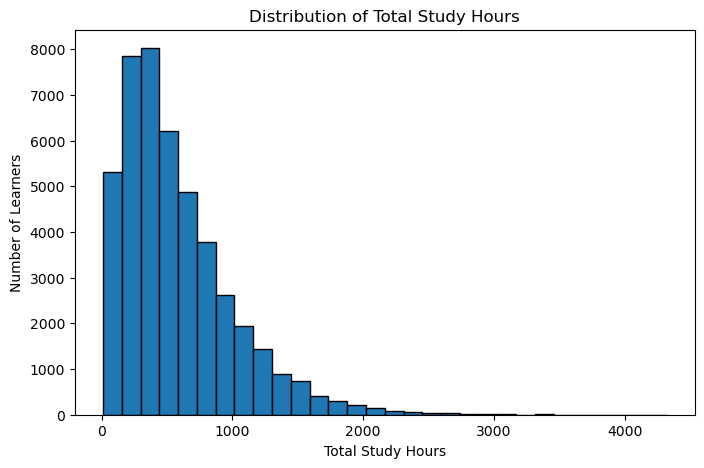

In [77]:
plt.figure(figsize=(8, 5))
plt.hist(df["total_study_hours"], bins=30, edgecolor="black")

plt.title("Distribution of Total Study Hours")
plt.xlabel("Total Study Hours")
plt.ylabel("Number of Learners")

plt.show()

In [78]:
# Calculate skewness of total study hours
study_hours_skewness = df["total_study_hours"].skew()

print("Skewness:", round(study_hours_skewness, 3))

Skewness: 1.508


In [79]:
# Create a log-transformed version of study hours
y_study_hours_log = np.log1p(y_study_hours)

# Check the transformed target
print("Original target skewness:", round(y_study_hours.skew(), 3))
print("Log-transformed target skewness:", round(y_study_hours_log.skew(), 3))

Original target skewness: 1.508
Log-transformed target skewness: -0.763


In [80]:
# Split the log-transformed target using the same random state
X_train_study_hours, X_test_study_hours, y_train_study_hours_log, y_test_study_hours_log = train_test_split(
    X_study_hours,
    y_study_hours_log,
    test_size=0.2,
    random_state=42
)

print("Training data shape:", X_train_study_hours.shape)
print("Testing data shape:", X_test_study_hours.shape)

Training data shape: (36000, 12)
Testing data shape: (9000, 12)


In [81]:
# Create the Linear Regression model
lr_log_study_hours_model = LinearRegression()

# Train using the log-transformed target
lr_log_study_hours_model.fit(
    X_train_study_hours,
    y_train_study_hours_log
)

print("Linear Regression with log-transformed target trained successfully!")

Linear Regression with log-transformed target trained successfully!


In [82]:
# Predict log-transformed study hours
y_pred_log_study_hours = lr_log_study_hours_model.predict(
    X_test_study_hours
)

# Convert predictions back to actual study hours
y_pred_log_study_hours = np.expm1(y_pred_log_study_hours)

# Get actual study hours for the same test samples
y_test_study_hours_original = np.expm1(y_test_study_hours_log)

# Calculate evaluation metrics
mae_log_study_hours = mean_absolute_error(
    y_test_study_hours_original,
    y_pred_log_study_hours
)

rmse_log_study_hours = np.sqrt(
    mean_squared_error(
        y_test_study_hours_original,
        y_pred_log_study_hours
    )
)

r2_log_study_hours = r2_score(
    y_test_study_hours_original,
    y_pred_log_study_hours
)

print("MAE:", round(mae_log_study_hours, 4))
print("RMSE:", round(rmse_log_study_hours, 4))
print("R2 Score:", round(r2_log_study_hours, 4))

MAE: 321.2756
RMSE: 454.0155
R2 Score: -0.1332


In [83]:
# Display Random Forest feature importance
study_hours_importance = pd.DataFrame({
    "Feature": X_study_hours.columns,
    "Importance": rf_study_hours_model.feature_importances_
})

study_hours_importance = study_hours_importance.sort_values(
    by="Importance",
    ascending=False
)

study_hours_importance

,Feature,Importance
4,active_use_share,0.130851
9,motivation,0.130180
7,feedback_quality,0.127632
11,accent_nativelike,0.126890
6,speaking_practice,0.124916
10,consistency,0.122444
3,age_started,0.089808
5,immersion_months,0.055185
0,fsi_category,0.033200
2,prior_languages,0.030190


#### Drop the prediction of total study hours 

Since there are no features that can contribute sufficiently, it is not possible to predict the total study hours (From the available features). 

In [84]:
# Summary statistics for accent score
df["accent_nativelike"].describe()

count    45000.000000
mean         5.702435
std          1.963940
min          0.000000
25%          4.370000
50%          5.720000
75%          7.060000
max         10.000000
Name: accent_nativelike, dtype: float64

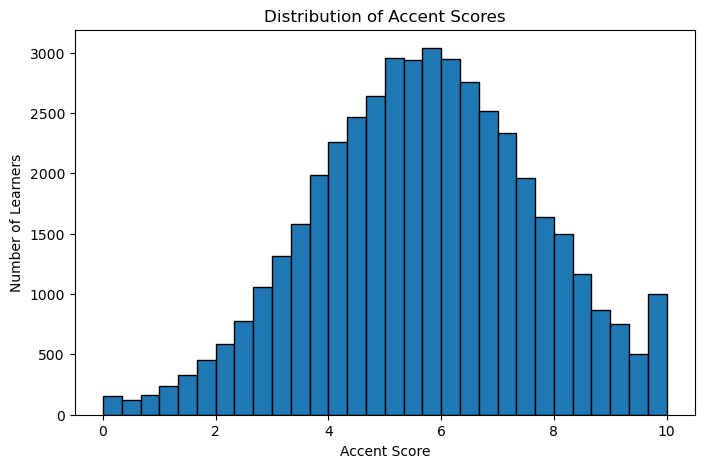

In [85]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["accent_nativelike"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Accent Scores")
plt.xlabel("Accent Score")
plt.ylabel("Number of Learners")

plt.show()

In [86]:
# Check correlations with accent score
accent_correlations = (
    df.corr(numeric_only=True)["accent_nativelike"]
    .sort_values(ascending=False)
)

accent_correlations

accent_nativelike             1.000000
immersion_months              0.061879
feedback_quality              0.008154
uses_srs                      0.005040
consistency                   0.004233
fsi_category                  0.004232
related_language              0.003837
motivation                    0.003557
reached_fluency               0.002828
active_use_share             -0.000498
prior_languages              -0.002789
speaking_practice            -0.005187
comprehensible_input_hours   -0.006234
total_study_hours            -0.006931
dropped_out                  -0.007711
age_started                  -0.652900
Name: accent_nativelike, dtype: float64

In [87]:
# Import the required libraries
from sklearn.svm import SVR

In [88]:


# Create the SVR model
svr_accent_model = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf")
)

# Train the model
svr_accent_model.fit(X_train_accent, y_train_accent)

print("SVR accent model trained successfully!")

SVR accent model trained successfully!


In [89]:
# Make predictions using SVR
y_pred_svr_accent = svr_accent_model.predict(X_test_accent)

# Calculate evaluation metrics
mae_svr_accent = mean_absolute_error(
    y_test_accent, y_pred_svr_accent
)

rmse_svr_accent = np.sqrt(
    mean_squared_error(y_test_accent, y_pred_svr_accent)
)

r2_svr_accent = r2_score(
    y_test_accent, y_pred_svr_accent
)

# Compare all four models
accent_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
        "SVR"
    ],
    "MAE": [
        mae_accent,
        mae_rf_accent,
        mae_gb_accent,
        mae_svr_accent
    ],
    "RMSE": [
        rmse_accent,
        rmse_rf_accent,
        rmse_gb_accent,
        rmse_svr_accent
    ],
    "R2 Score": [
        r2_accent,
        r2_rf_accent,
        r2_gb_accent,
        r2_svr_accent
    ]
})

accent_comparison.round(4)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.1959,1.4892,0.4280
1,Random Forest,1.2180,1.5185,0.4052
2,Gradient Boosting,1.1979,1.4925,0.4255
3,SVR,1.2092,1.5076,0.4138


In [90]:
# Create a DataFrame to examine prediction errors
accent_error_analysis = pd.DataFrame({
    "Age Started": X_test_accent["age_started"],
    "Actual Accent Score": y_test_accent,
    "Predicted Accent Score": accent_model.predict(X_test_accent)
})

# Calculate prediction error
accent_error_analysis["Error"] = (
    accent_error_analysis["Actual Accent Score"]
    - accent_error_analysis["Predicted Accent Score"]
)

# Group learners by age and examine average errors
accent_error_analysis["Age Group"] = pd.cut(
    accent_error_analysis["Age Started"],
    bins=[0, 10, 18, 30, 100],
    labels=["0-10", "11-18", "19-30", "31+"]
)

accent_error_analysis.groupby(
    "Age Group", observed=False
)["Error"].agg(["mean", "std", "count"]).round(3)

,mean,std,count
Age Group,,,
0-10,0.028,1.352,482
11-18,0.067,1.482,1237
19-30,-0.018,1.483,3582
31+,-0.047,1.514,3699


In [91]:
# Create a copy of the accent features
X_accent_poly = X_accent.copy()

# Add a squared age feature
X_accent_poly["age_started_squared"] = (
    X_accent_poly["age_started"] ** 2
)

# Use the same train-test split
X_train_accent_poly, X_test_accent_poly, y_train_accent_poly, y_test_accent_poly = train_test_split(
    X_accent_poly,
    y_accent,
    test_size=0.2,
    random_state=42
)

print("Training shape:", X_train_accent_poly.shape)
print("Testing shape:", X_test_accent_poly.shape)

Training shape: (36000, 14)
Testing shape: (9000, 14)


In [92]:
# Train Linear Regression with the additional squared-age feature
lr_poly_accent_model = LinearRegression()

lr_poly_accent_model.fit(
    X_train_accent_poly,
    y_train_accent_poly
)

print("Linear Regression with squared-age feature trained successfully!")

Linear Regression with squared-age feature trained successfully!


In [93]:
# Make predictions using the model with the squared-age feature
y_pred_poly_accent = lr_poly_accent_model.predict(X_test_accent_poly)

# Calculate evaluation metrics
mae_poly_accent = mean_absolute_error(
    y_test_accent_poly, y_pred_poly_accent
)

rmse_poly_accent = np.sqrt(
    mean_squared_error(y_test_accent_poly, y_pred_poly_accent)
)

r2_poly_accent = r2_score(
    y_test_accent_poly, y_pred_poly_accent
)

# Display the results
print("Linear Regression with Squared-Age Feature")
print("MAE:", round(mae_poly_accent, 4))
print("RMSE:", round(rmse_poly_accent, 4))
print("R² Score:", round(r2_poly_accent, 4))

Linear Regression with Squared-Age Feature
MAE: 1.1959
RMSE: 1.4892
R² Score: 0.428


## Final Model Selection and Evaluation

### 1. Objective

The objective of this stage was to train, evaluate, and compare machine learning models for predicting different aspects of language learning. Multiple models were tested where appropriate, and the final model for each task was selected based on its evaluation results.

### 2. Final Models

| Prediction Task | Selected Model | Evaluation |
|---|---|---|
| Fluency Prediction | Random Forest Classifier | Accuracy: 89.50% |
| Dropout Prediction | Gradient Boosting Classifier | Accuracy: 73.76% |
| CEFR Level Prediction | Random Forest Classifier | Accuracy: approximately 57% |
| Accent Score Prediction | Linear Regression | MAE: 1.1959, RMSE: 1.4892, R²: 0.4280 |

### 3. Study Hours Prediction

The study-hours prediction task was discontinued because the tested regression models produced weak results. Their R² scores were close to zero or negative, indicating that they did not meaningfully explain variation in study hours.

Therefore, this model will not be included in the final deployed interface.

### 4. Accent Score Model Analysis

Linear Regression achieved an MAE of 1.1959, RMSE of 1.4892, and R² of 0.4280.

An additional experiment introduced a squared-age feature to test whether a nonlinear age relationship could improve predictions. The evaluation metrics remained unchanged, so the original Linear Regression model was retained because it is simpler.

### 5. Limitations

- The fluency and dropout models do not predict every learner correctly.
- CEFR classification remains challenging, with differences in performance across proficiency levels.
- The accent model explains approximately 42.8% of the variation in accent scores on the test set.
- Study-hours prediction did not achieve satisfactory performance with the tested features and models.

### 6. Deployment Plan

The four selected trained models will be saved for later use in an interactive application. Users will be able to provide input features and obtain predictions from the relevant model without retraining it for every request.


In [95]:
import joblib
import os

In [96]:
# Create a directory to store the trained models
os.makedirs("models", exist_ok=True)

print("Models directory is ready!")

Models directory is ready!


In [97]:
# Save the Fluency Prediction model
joblib.dump(fluency_model, "models/fluency_model.pkl")

# Save the Dropout Prediction model
joblib.dump(dropout_model, "models/dropout_model.pkl")

# Save the CEFR Level Prediction model
joblib.dump(cefr_model, "models/cefr_model.pkl")

# Save the Accent Score Prediction model
joblib.dump(accent_model, "models/accent_model.pkl")

print("All four models saved successfully!")

All four models saved successfully!


In [98]:
# List all files in the models directory
print(os.listdir("models"))

['accent_model.pkl', 'cefr_model.pkl', 'dropout_model.pkl', 'fluency_model.pkl']
